# Comparative Analysis: EpiHydra vs. Linear Clocks under Missingness

This notebook analyses how EpiHydra compares to PC clocks and linear clock implementations under two CpG-missingness strategies:

| Strategy | Description |
|---|---|
| **Random masking** | A random fraction of each sample's observed CpGs are masked — simulates uniform data-quality degradation |
| **Systematic removal** | High-variance CpGs are removed first — simulates targeted assay or genomic-region failure |

Models compared:
- **EpiHydra** — transformer-based clock, raw (missing CpGs stay masked)
- **PC clocks** — principal-component versions of each clock (Higgins-Chen et al., 2022), run via `pyaging`; missing CpGs replaced by the per-CpG training-cohort reference
- **Linear** — conventional elastic-net / linear clock (uses imputed values by design)

Figures are production-ready at **Nature Medicine** specifications (300 dpi, Arial, single-column 89 mm).

## 0 · Imports & configuration

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D

from evaluation import eval_utils as eu 
from evaluation.eval_utils import (
    _NM_RC,   # Nature Medicine rcParams
    _MM,      # mm → inches
    _clean,   # readable clock labels
    _METRIC_LABEL,
    _HIGH_IS_GOOD,
    compute_metrics,
    plot_missing_fraction_curves,
    plot_systematic_removal_curves,
)

# ── Output directory ─────────────────────────────────────────────────────────
SAVE_DIR = Path('/work/gr-fe/bryan/EpiHydra/results/figures/')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# ── Clock names present in ALL result DataFrames ─────────────────────────────
# Adjust this list to match the clocks actually in your CSVs
CLOCK_NAMES = ['horvath_age', 'phenoage_age', 'hannum_age']  # <- edit if needed

print('eval_utils version:', getattr(eu, '__version__', 'n/a'))
print('Clocks analysed   :', CLOCK_NAMES)
print('Figures saved to  :', SAVE_DIR.resolve())

/work/gr-fe/bryan/miniconda3/envs/methylgpt/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


eval_utils version: n/a
Clocks analysed   : ['horvath_age', 'phenoage_age', 'hannum_age']
Figures saved to  : /work/gr-fe/bryan/EpiHydra/results/figures


## 1 · Load pre-computed results

Each CSV is a long-form table produced by `evaluate_missing_fraction` / `evaluate_systematic_removal` and contains columns:
`clock`, `mask_frac` or `removal_frac`, `total_missing`, `n`, `mae`, `pearson_r`, `r2`.

> The linear and PC clock results are expected in the same long format; if yours differ, reshape in the cell below. The PC clock CSVs also carry `*_self` columns (metrics against each PC clock's own 0% prediction); they are ignored here and appear as NaN for the other models after concatenation.

In [2]:
BASE = Path('/work/gr-fe/bryan/EpiHydra/results')

# ── EpiHydra results ─────────────────────────────────────────────────────────
epihydra_random     = pd.read_csv(BASE / 'mask_results.csv',       index_col=0)
epihydra_systematic = pd.read_csv(BASE / 'systematic_results.csv', index_col=0)

# ── PC clock results (08_PCClocks.ipynb) ─────────────────────────────────────
pc_random     = pd.read_csv(BASE / 'pcclocks_results_random.csv',     index_col=0)
pc_systematic = pd.read_csv(BASE / 'pcclocks_results_systematic.csv', index_col=0)

# ── Linear clock results ──────────────────────────────────────────────────────
linear_random     = pd.read_csv(BASE / 'linear_results_random.csv')
linear_systematic = pd.read_csv(BASE / 'linear_results_systematic.csv')

# ── Annotate model identity (for combined plots) ─────────────────────────────
epihydra_random.insert(0,     'model', 'EpiHydra')
epihydra_systematic.insert(0, 'model', 'EpiHydra')
pc_random.insert(0,           'model', 'PC clocks')
pc_systematic.insert(0,       'model', 'PC clocks')
linear_random.insert(0,       'model', 'Linear')
linear_systematic.insert(0,   'model', 'Linear')

# ── Combined long tables ──────────────────────────────────────────────────────
random_all     = pd.concat([epihydra_random, pc_random, linear_random],
                            ignore_index=True)
systematic_all = pd.concat([epihydra_systematic, pc_systematic, linear_systematic],
                            ignore_index=True)

# ── Sanity check ─────────────────────────────────────────────────────────────
print('Random missingness results')
print(random_all.groupby('model')['clock'].unique().to_string())
print()
print('Systematic removal results')
print(systematic_all.groupby('model')['clock'].unique().to_string())

Random missingness results
model
EpiHydra     [age, hannum_age, horvath_age, phenoage_age]
Linear            [horvath_age, hannum_age, phenoage_age]
PC clocks         [horvath_age, hannum_age, phenoage_age]

Systematic removal results
model
EpiHydra     [age, hannum_age, horvath_age, phenoage_age]
Linear            [horvath_age, hannum_age, phenoage_age]
PC clocks         [horvath_age, hannum_age, phenoage_age]


## 2 · Colour & style palette

We define a consistent, colour-blind-friendly palette for the three models. Line styles further differentiate them in greyscale / print.

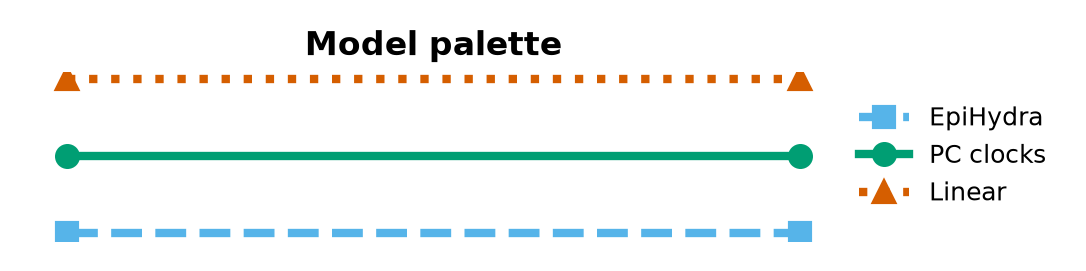

In [3]:
# Okabe–Ito palette (Nature-recommended, colour-blind safe)
MODEL_STYLE = {
    'EpiHydra':  {'color': '#56B4E9', 'ls': '--', 'marker': 's', 'lw': 1.0, 'zorder': 3},
    'PC clocks': {'color': '#009E73', 'ls': '-',  'marker': 'o', 'lw': 1.2, 'zorder': 4},
    'Linear':    {'color': '#D55E00', 'ls': ':',  'marker': '^', 'lw': 1.0, 'zorder': 2},
}
MODEL_ORDER = ['EpiHydra', 'PC clocks', 'Linear']

# Quick palette preview
with plt.rc_context(_NM_RC):
    fig, ax = plt.subplots(figsize=(89 * _MM, 20 * _MM), constrained_layout=True)
    for i, (name, s) in enumerate(MODEL_STYLE.items()):
        ax.plot([0, 1], [i, i], color=s['color'], ls=s['ls'],
                lw=2, marker=s['marker'], markersize=5, label=name)
    ax.legend(frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))
    ax.set_axis_off()
    ax.set_title('Model palette', pad=4, fontweight='bold')
plt.show()

## 3 · Custom comparative plotting helpers

These extend the `eval_utils` plotting functions to overlay all three models on the same axes.

In [4]:
def _legend_handles(models=MODEL_ORDER):
    """Shared legend handles for all comparative figures."""
    return [
        Line2D([0], [0],
               color=MODEL_STYLE[m]['color'],
               ls=MODEL_STYLE[m]['ls'],
               lw=MODEL_STYLE[m]['lw'],
               marker=MODEL_STYLE[m]['marker'],
               markersize=4,
               label=m)
        for m in models
    ]


def plot_comparative_curves(
    combined_df,
    clock_names,
    metric='mae',
    x='total_missing',
    strategy_title='Random missingness',
    save_path=None,
):
    """
    One subplot per clock, all three models overlaid.
    Uses _NM_RC and MODEL_STYLE for Nature Medicine conformant output.

    Parameters
    ----------
    combined_df    : concatenated long DataFrame with a 'model' column
    clock_names    : list of clock identifiers to plot
    metric         : 'mae' | 'pearson_r' | 'r2'
    x              : column to use as x-axis ('total_missing' | 'mask_frac' | 'removal_frac')
    strategy_title : figure super-title prefix
    save_path      : Path or str (without extension); saves SVG + PDF
    """
    n = len(clock_names)
    xlabel = {
        'total_missing': 'Total CpGs missing (%)',
        'mask_frac':     'Additional CpGs masked (%)',
        'removal_frac':  'CpGs removed (fraction)',
    }.get(x, x)

    # Double-column figure for ≥3 clocks, single-column otherwise
    fig_w = min(183, 55 * n) * _MM
    fig_h = 65 * _MM

    with plt.rc_context(_NM_RC):
        fig, axes = plt.subplots(1, n,
                                 figsize=(fig_w, fig_h),
                                 sharey=True,
                                 constrained_layout=True,
                                 squeeze=False)
        axes = axes[0]

        for ax, clock in zip(axes, clock_names):
            for model in MODEL_ORDER:
                sub = combined_df[
                    (combined_df['clock'] == clock) &
                    (combined_df['model'] == model)
                ].sort_values(x)
                if sub.empty:
                    continue
                s = MODEL_STYLE[model]
                xvals = sub[x] * 100 if 'frac' in x or x == 'total_missing' else sub[x]
                ax.plot(
                    xvals, sub[metric],
                    color=s['color'], ls=s['ls'],
                    lw=s['lw'], marker=s['marker'],
                    markersize=3, zorder=s['zorder'],
                )

            ax.set_title(_clean(clock), pad=4, fontweight='bold')
            ax.set_xlabel(xlabel + ('' if 'frac' in x or x == 'total_missing' else ''))
            ax.set_ylim(bottom=0)
            ax.set_xlim(left=0)
            ax.set_xticks([0, 10, 25, 50, 75, 100])
            ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.1f'))


        axes[0].set_ylabel(_METRIC_LABEL[metric])

        # Shared legend on the last subplot
        axes[-1].legend(
            handles=_legend_handles(),
            frameon=False,
            fontsize=5,
            loc='best',
        )
        fig.suptitle(
            f'{strategy_title} — {_METRIC_LABEL[metric]}',
            fontsize=8, fontweight='bold',
        )

    if save_path is not None:
        for fmt in ('svg', 'pdf'):
            p = Path(str(save_path) + f'.{fmt}')
            p.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(p)
            print(f'Saved → {p}')

    return fig, axes


def plot_summary_heatmap(
    combined_df,
    clock_names,
    metric='mae',
    missing_col='total_missing',
    missing_levels=None,
    save_path=None,
):
    """
    Heatmap: rows = models, columns = missingness level, one panel per clock.
    Colour encodes the metric value (green = better).

    missing_levels : specific quantiles to show (default: 0%, 25%, 50%, 75%, 100%)
    """
    cmap = 'RdYlGn_r' if not _HIGH_IS_GOOD[metric] else 'RdYlGn'
    n = len(clock_names)

    with plt.rc_context(_NM_RC):
        fig, axes = plt.subplots(1, n,
                                 figsize=(min(183, 55 * n) * _MM, 55 * _MM),
                                 constrained_layout=True,
                                 squeeze=False)
        axes = axes[0]

        for ax, clock in zip(axes, clock_names):
            sub = combined_df[combined_df['clock'] == clock].copy()

            # Snap to nearest measured level
            if missing_levels is None:
                q = sub[missing_col].quantile([0, 0.25, 0.5, 0.75, 1.0]).values
            else:
                q = np.asarray(missing_levels)

            def _nearest(val, candidates):
                return candidates[np.argmin(np.abs(candidates - val))]

            sub['level'] = sub[missing_col].apply(_nearest, candidates=q)
            pivot = sub.groupby(['model', 'level'])[metric].mean().unstack('level')
            pivot = pivot.reindex(index=MODEL_ORDER)
            pivot.columns = [f'{int(c*100)}%' for c in pivot.columns]

            # Colour limits from visible cells only
            vals = pivot.to_numpy()[np.isfinite(pivot.to_numpy())]
            vmin, vmax = (vals.min(), vals.max()) if vals.size else (None, None)

            sns.heatmap(
                pivot, annot=True, fmt='.2f',
                cmap=cmap, vmin=vmin, vmax=vmax,
                linewidths=0.4, linecolor='white',
                ax=ax, cbar=(ax is axes[-1]),
                annot_kws={'fontsize': 5},
            )
            ax.set_title(_clean(clock), pad=4, fontweight='bold')
            ax.set_xlabel('Total CpGs missing (%)')
            ax.set_ylabel('Model' if ax is axes[0] else '')
            ax.tick_params(axis='both', labelsize=5)

        fig.suptitle(
            f'{_METRIC_LABEL[metric]} by model and missingness level',
            fontsize=8, fontweight='bold',
        )

    if save_path is not None:
        for fmt in ('svg', 'pdf'):
            p = Path(str(save_path) + f'.{fmt}')
            p.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(p)
            print(f'Saved → {p}')

    return fig, axes


def plot_delta_improvement(
    combined_df,
    clock_names,
    baseline='Linear',
    metric='mae',
    x='total_missing',
    strategy_title='Random missingness',
    save_path=None,
):
    """
    Signed improvement of each model over `baseline` (Δ metric).
    For MAE: positive Δ = the model is worse (higher error); we flip the sign
    so a positive value always means the model beats the baseline.

    One subplot per clock, one line per non-baseline model (EpiHydra, PC clocks).
    A horizontal reference line at y=0 marks parity with the baseline.
    """
    challengers = [m for m in MODEL_ORDER if m != baseline]
    n = len(clock_names)
    xlabel = {
        'total_missing': 'Total CpGs missing (%)',
        'mask_frac':     'Additional CpGs masked (%)',
        'removal_frac':  'CpGs removed (fraction)',
    }.get(x, x)

    sign = -1 if not _HIGH_IS_GOOD[metric] else 1   # flip so positive = better

    with plt.rc_context(_NM_RC):
        fig, axes = plt.subplots(1, n,
                                 figsize=(min(183, 55 * n) * _MM, 65 * _MM),
                                 sharey=True,
                                 constrained_layout=True,
                                 squeeze=False)
        axes = axes[0]

        for ax, clock in zip(axes, clock_names):
            base_sub = combined_df[
                (combined_df['clock'] == clock) &
                (combined_df['model'] == baseline)
            ].set_index(x)[metric]

            for model in challengers:
                sub = combined_df[
                    (combined_df['clock'] == clock) &
                    (combined_df['model'] == model)
                ].sort_values(x)
                if sub.empty:
                    continue

                # Align on shared x values
                merged = sub.set_index(x)[metric].subtract(base_sub, fill_value=np.nan)
                delta  = merged * sign
                xvals  = merged.index * 100 if 'frac' in x or x == 'total_missing' else merged.index

                s = MODEL_STYLE[model]
                ax.plot(
                    xvals, delta,
                    color=s['color'], ls=s['ls'],
                    lw=s['lw'], marker=s['marker'],
                    markersize=3, zorder=s['zorder'],
                )

            ax.axhline(0, color='#888888', lw=0.6, ls='-', zorder=1,
                       label=f'Parity with {baseline}')
            ax.fill_between(ax.get_xlim(), 0, ax.get_ylim()[1] if ax.get_ylim()[1] > 0 else 1,
                            color='#0072B2', alpha=0.04, zorder=0)

            ax.set_title(_clean(clock), pad=4, fontweight='bold')
            ax.set_xlabel(xlabel + (' (%)' if 'frac' in x or x == 'total_missing' else ''))
            ax.set_xlim(left=0)
            ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.2f'))

        axes[0].set_ylabel(f'Δ {_METRIC_LABEL[metric]} vs. {baseline}\n(positive = better than {baseline})')

        legend_handles = _legend_handles(challengers)
        legend_handles.append(
            Line2D([0], [0], color='#888888', lw=0.6, label=f'Parity ({baseline})')
        )
        axes[-1].legend(handles=legend_handles, frameon=False, fontsize=5, loc='best')

        fig.suptitle(
            f'{strategy_title} — Improvement over {baseline} ({_METRIC_LABEL[metric]})',
            fontsize=8, fontweight='bold',
        )

    if save_path is not None:
        for fmt in ('svg', 'pdf'):
            p = Path(str(save_path) + f'.{fmt}')
            p.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(p)
            print(f'Saved → {p}')

    return fig, axes


print('Custom plot helpers registered.')

Custom plot helpers registered.


## 4 · Random missingness analysis

CpGs are masked uniformly at random within each sample. We show all three metrics (MAE, Pearson *r*, R²) for all three models across the full range of missingness fractions.

### 4.1 — Performance curves (all three metrics)

In [5]:
random_all

,model,clock,mask_frac,n,mae,pearson_r,r2,total_missing,n_boot,mae_self,pearson_r_self,r2_self,mae_sd,Unnamed: 0
0,EpiHydra,age,0.0,1239.0,4.669347,0.938785,0.866484,0.109903,NaN,NaN,NaN,NaN,NaN,NaN
1,EpiHydra,hannum_age,0.0,1239.0,3.154622,0.977603,0.934677,0.109903,NaN,NaN,NaN,NaN,NaN,NaN
2,EpiHydra,horvath_age,0.0,1239.0,3.093948,0.963084,0.919967,0.109903,NaN,NaN,NaN,NaN,NaN,NaN
3,EpiHydra,phenoage_age,0.0,1239.0,3.956660,0.958392,0.916640,0.109903,NaN,NaN,NaN,NaN,NaN,NaN
4,EpiHydra,age,0.1,1239.0,4.731170,0.935301,0.863247,0.198912,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,Linear,hannum_age,0.8,NaN,10.091783,0.915079,0.371308,0.800000,10.0,NaN,NaN,NaN,NaN,25.0
96,Linear,phenoage_age,0.8,NaN,12.545917,0.804062,0.218923,0.800000,10.0,NaN,NaN,NaN,NaN,26.0
97,Linear,horvath_age,0.9,NaN,11.863090,0.661441,0.095805,0.900000,10.0,NaN,NaN,NaN,NaN,27.0
98,Linear,hannum_age,0.9,NaN,11.520705,0.848725,0.176296,0.900000,10.0,NaN,NaN,NaN,NaN,28.0


Saved → /work/gr-fe/bryan/EpiHydra/results/figures/random_curves_mae.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/random_curves_mae.pdf


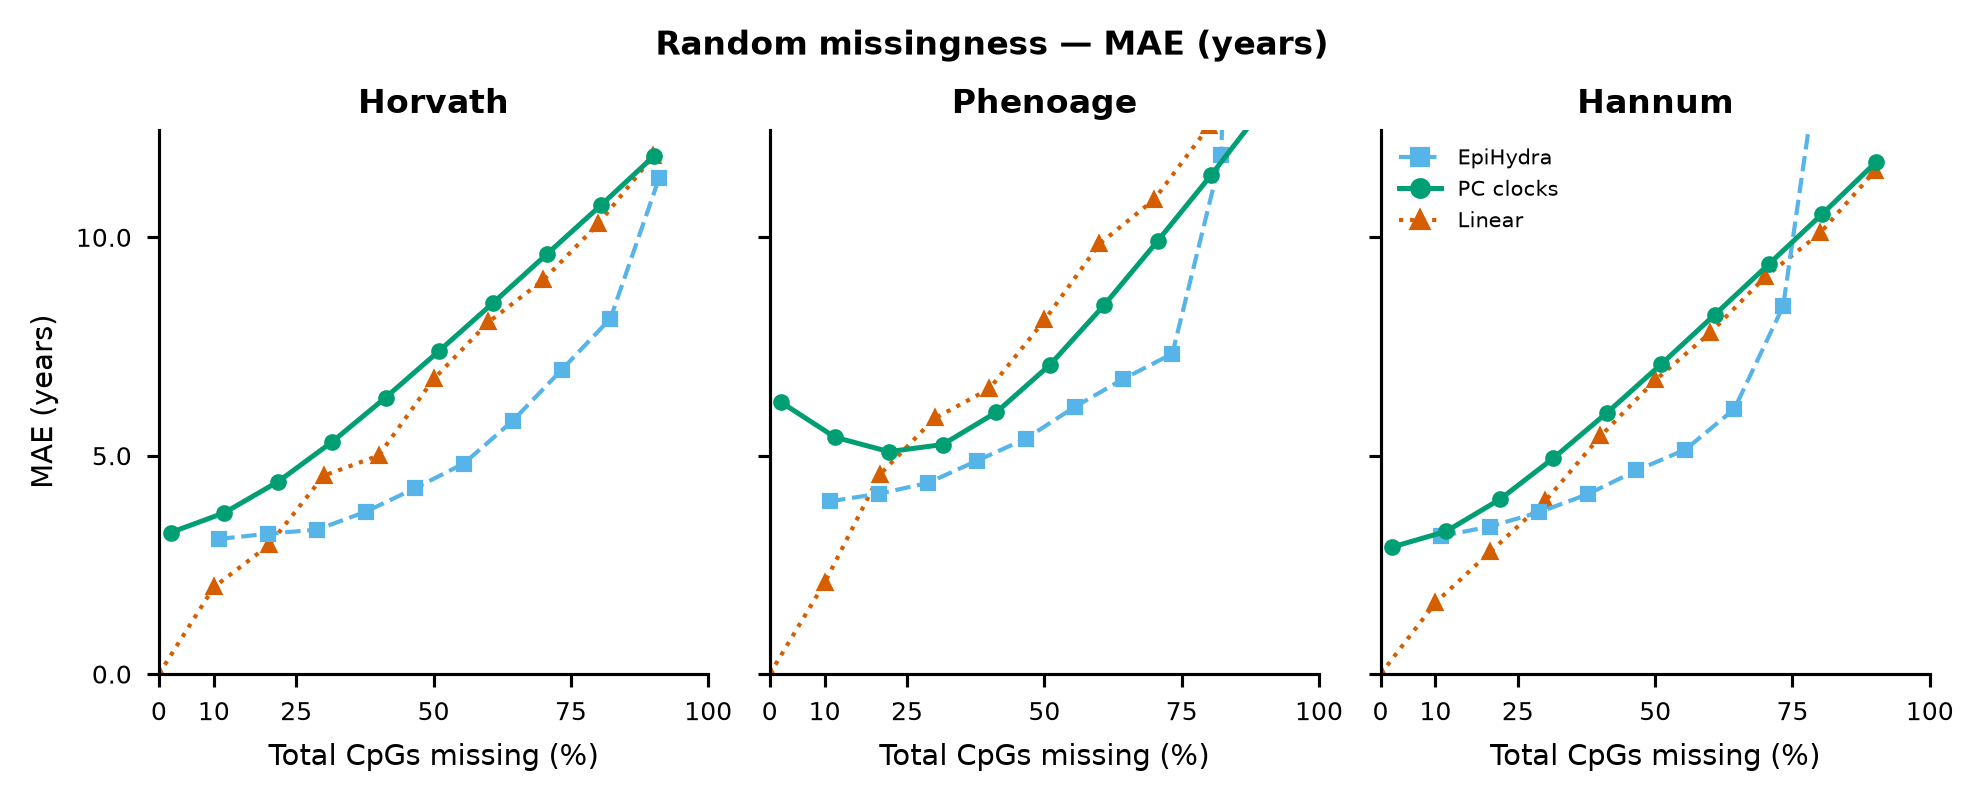

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/random_curves_pearson_r.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/random_curves_pearson_r.pdf


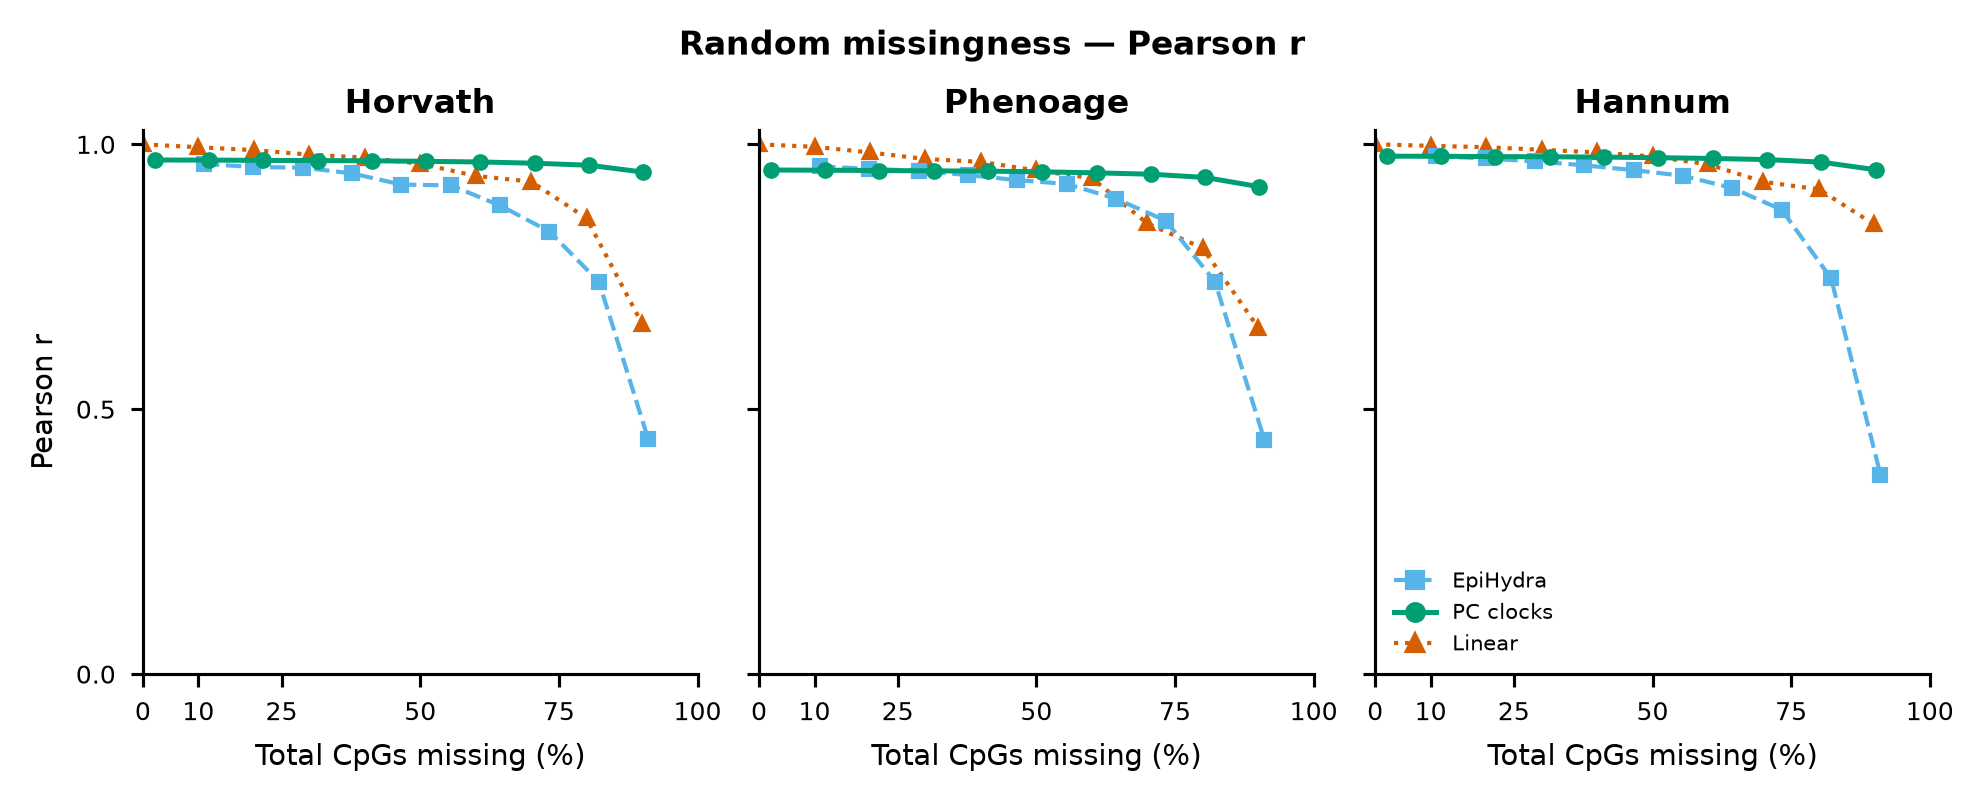

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/random_curves_r2.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/random_curves_r2.pdf


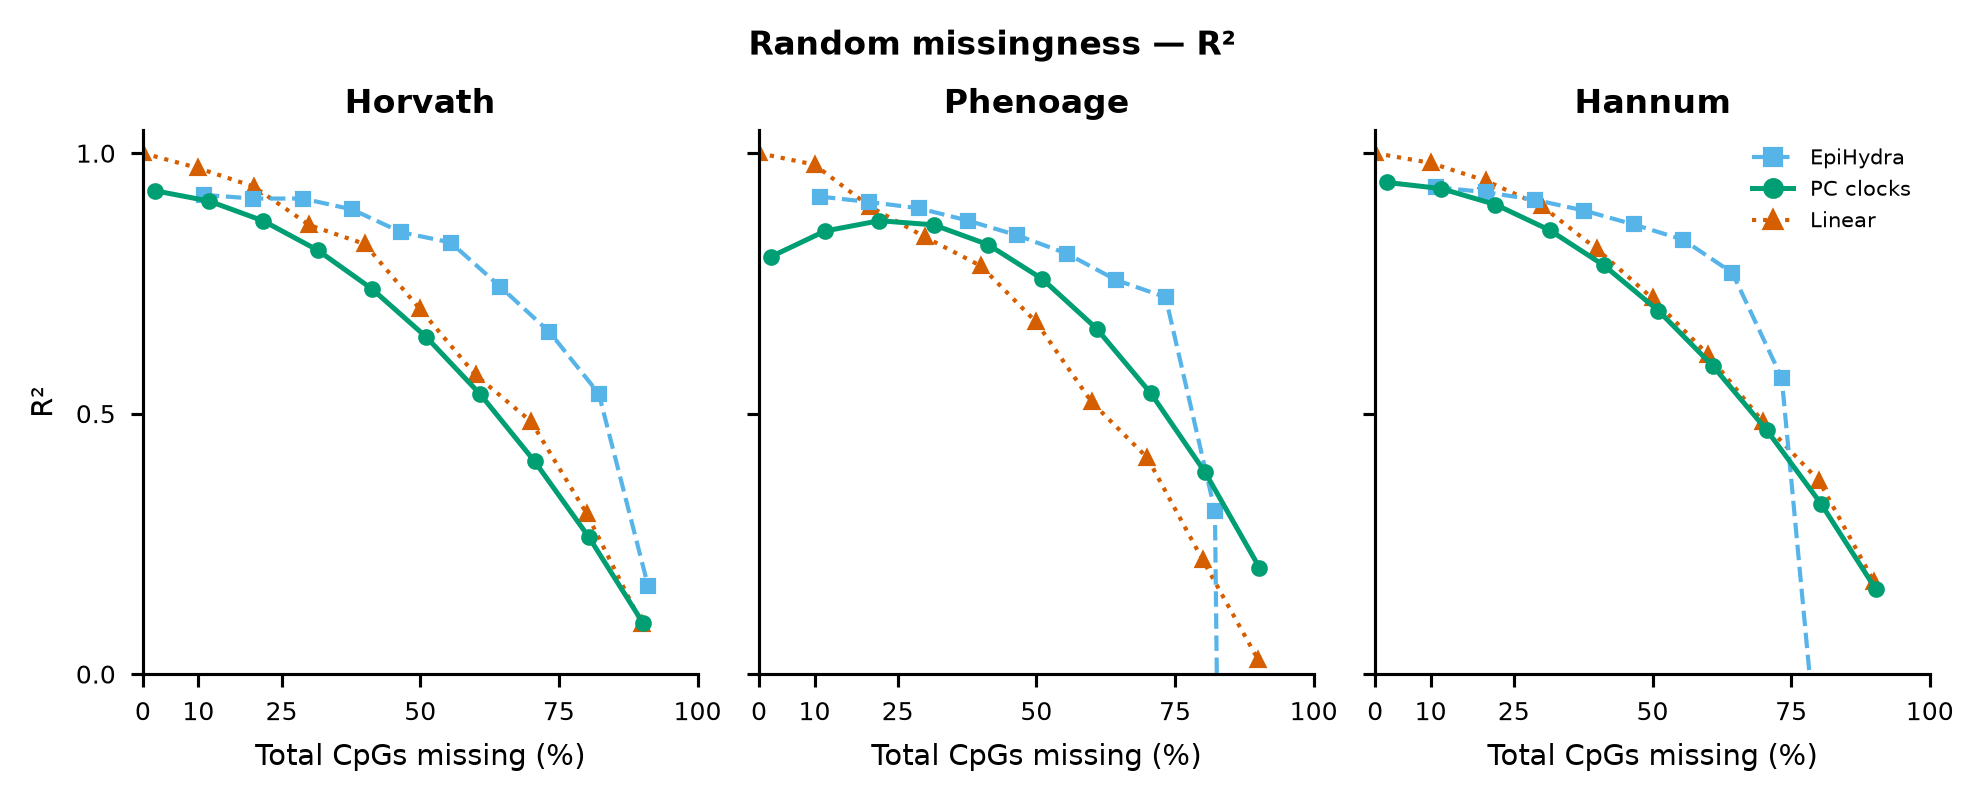

In [5]:
for metric in ('mae', 'pearson_r', 'r2'):
    fig, axes = plot_comparative_curves(
        random_all,
        clock_names=CLOCK_NAMES,
        metric=metric,
        x='total_missing',
        strategy_title='Random missingness',
        save_path=SAVE_DIR / f'random_curves_{metric}',
    )
    plt.show()

### 4.2 — Improvement over Linear (Δ MAE)

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/random_delta_mae.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/random_delta_mae.pdf


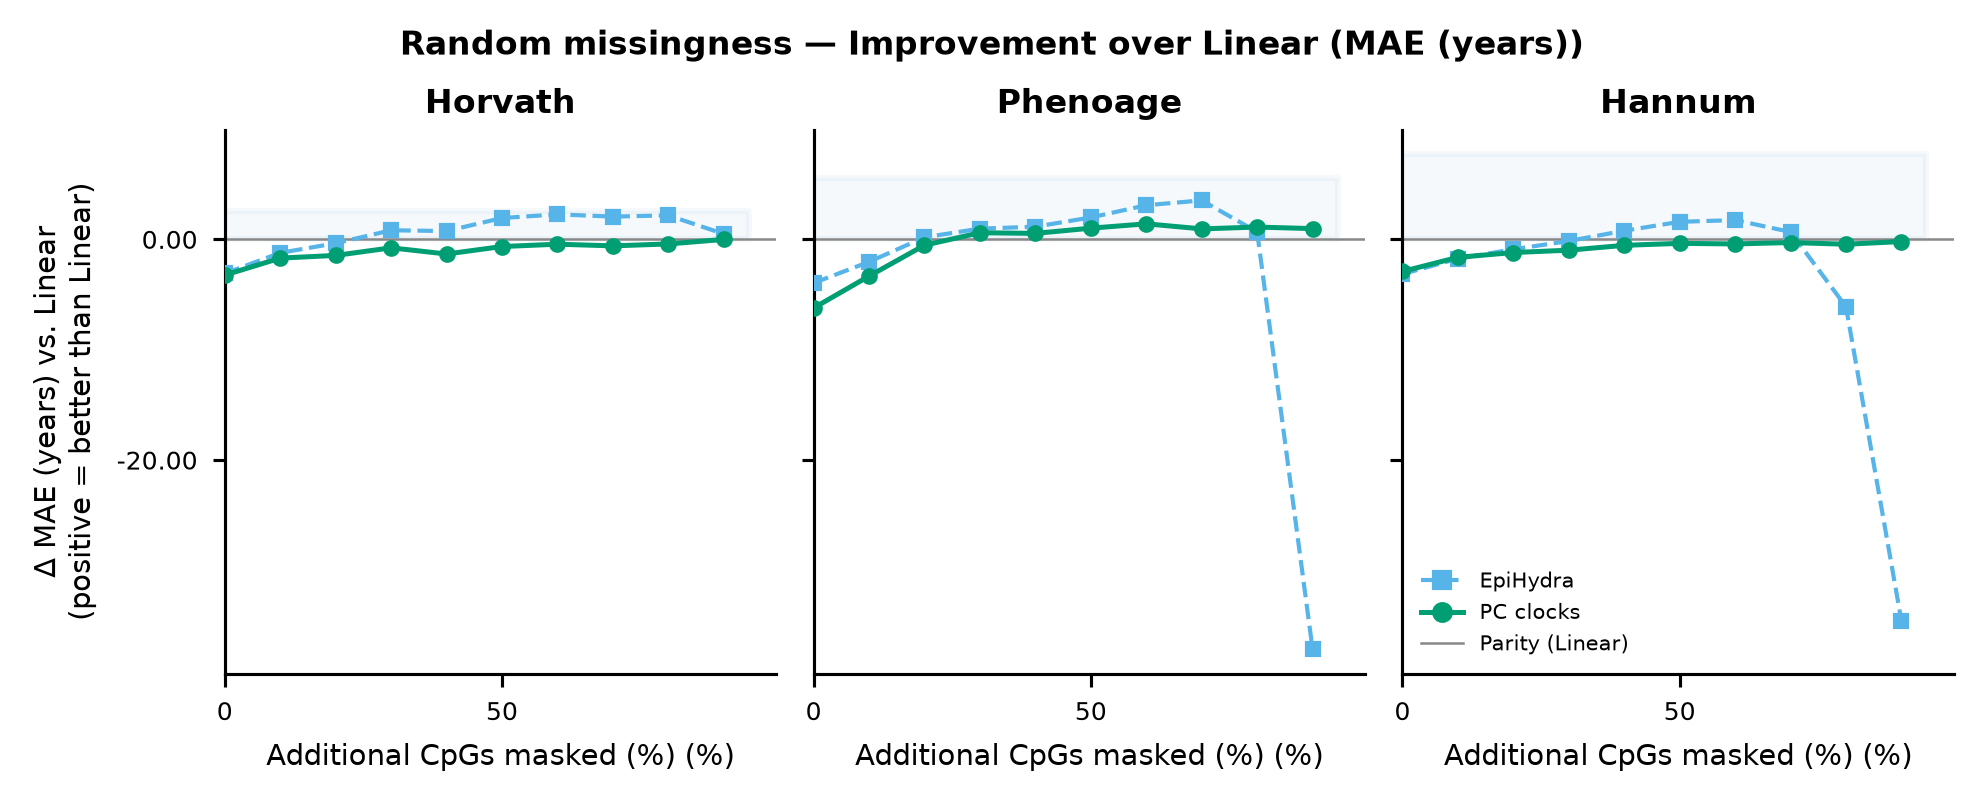

In [6]:
fig, axes = plot_delta_improvement(
    random_all,
    clock_names=CLOCK_NAMES,
    baseline='Linear',
    metric='mae',
    x='mask_frac',
    strategy_title='Random missingness',
    save_path=SAVE_DIR / 'random_delta_mae',
)
plt.show()

### 4.3 — Summary heatmap (MAE at key missingness levels)

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/random_heatmap_mae.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/random_heatmap_mae.pdf


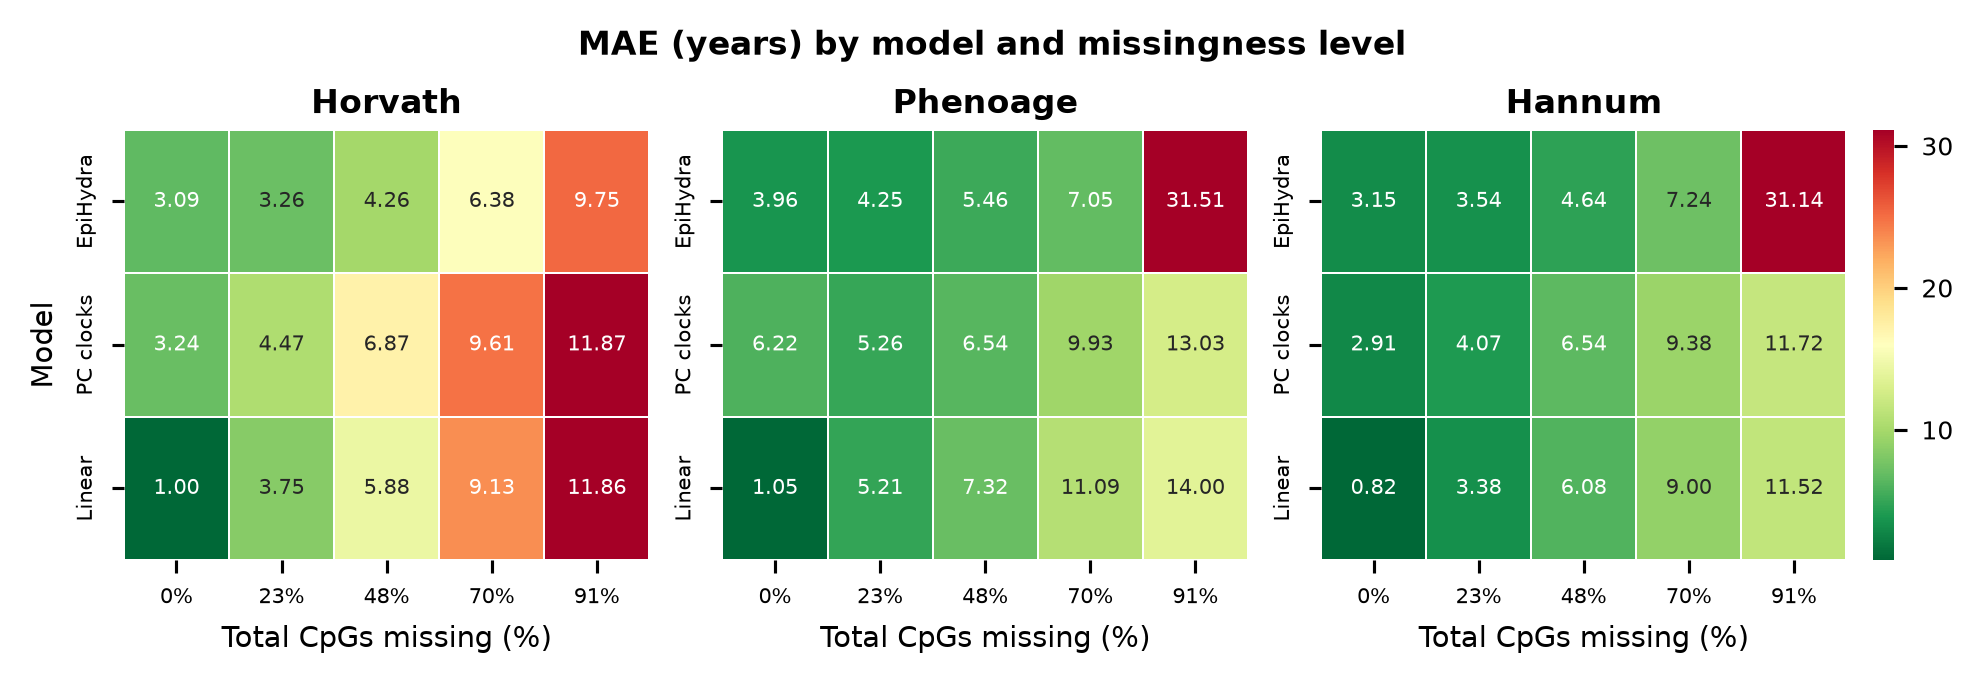

In [7]:
fig, axes = plot_summary_heatmap(
    random_all,
    clock_names=CLOCK_NAMES,
    metric='mae',
    missing_col='total_missing',
    save_path=SAVE_DIR / 'random_heatmap_mae',
)
plt.show()

## 5 · Systematic removal analysis (high-variance CpGs first)

High-variance CpGs are removed in descending variance order. This is the more demanding stress-test: the most informative probes are lost first.

### 5.1 — Performance curves (all three metrics)

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/systematic_curves_mae.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/systematic_curves_mae.pdf


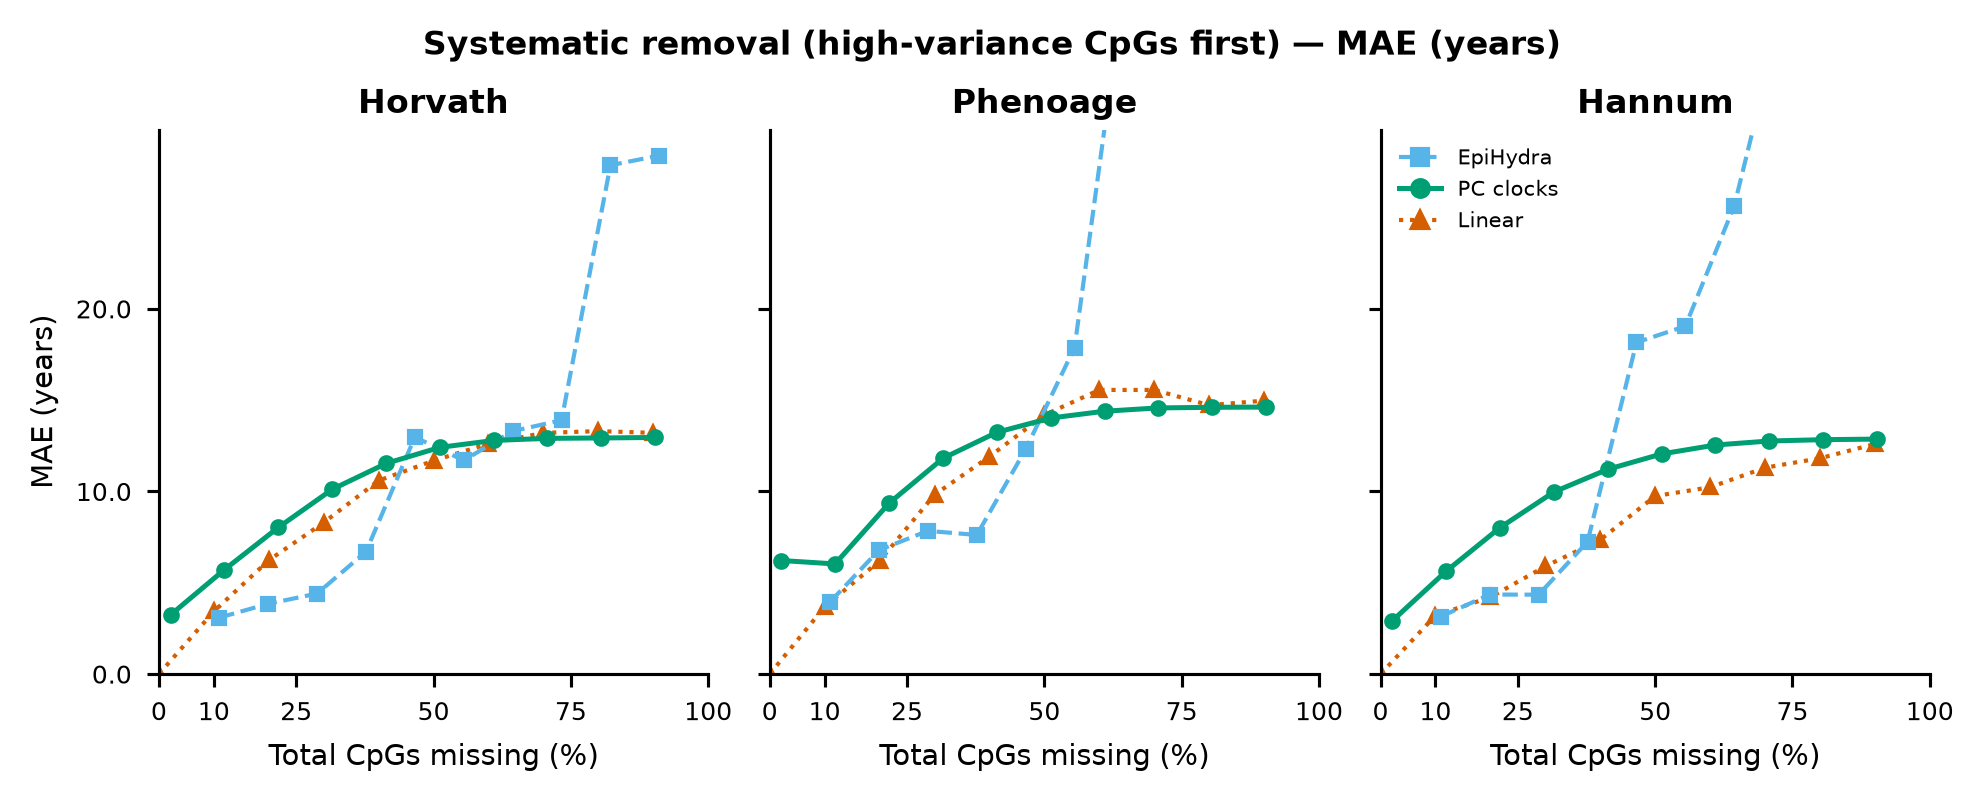

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/systematic_curves_pearson_r.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/systematic_curves_pearson_r.pdf


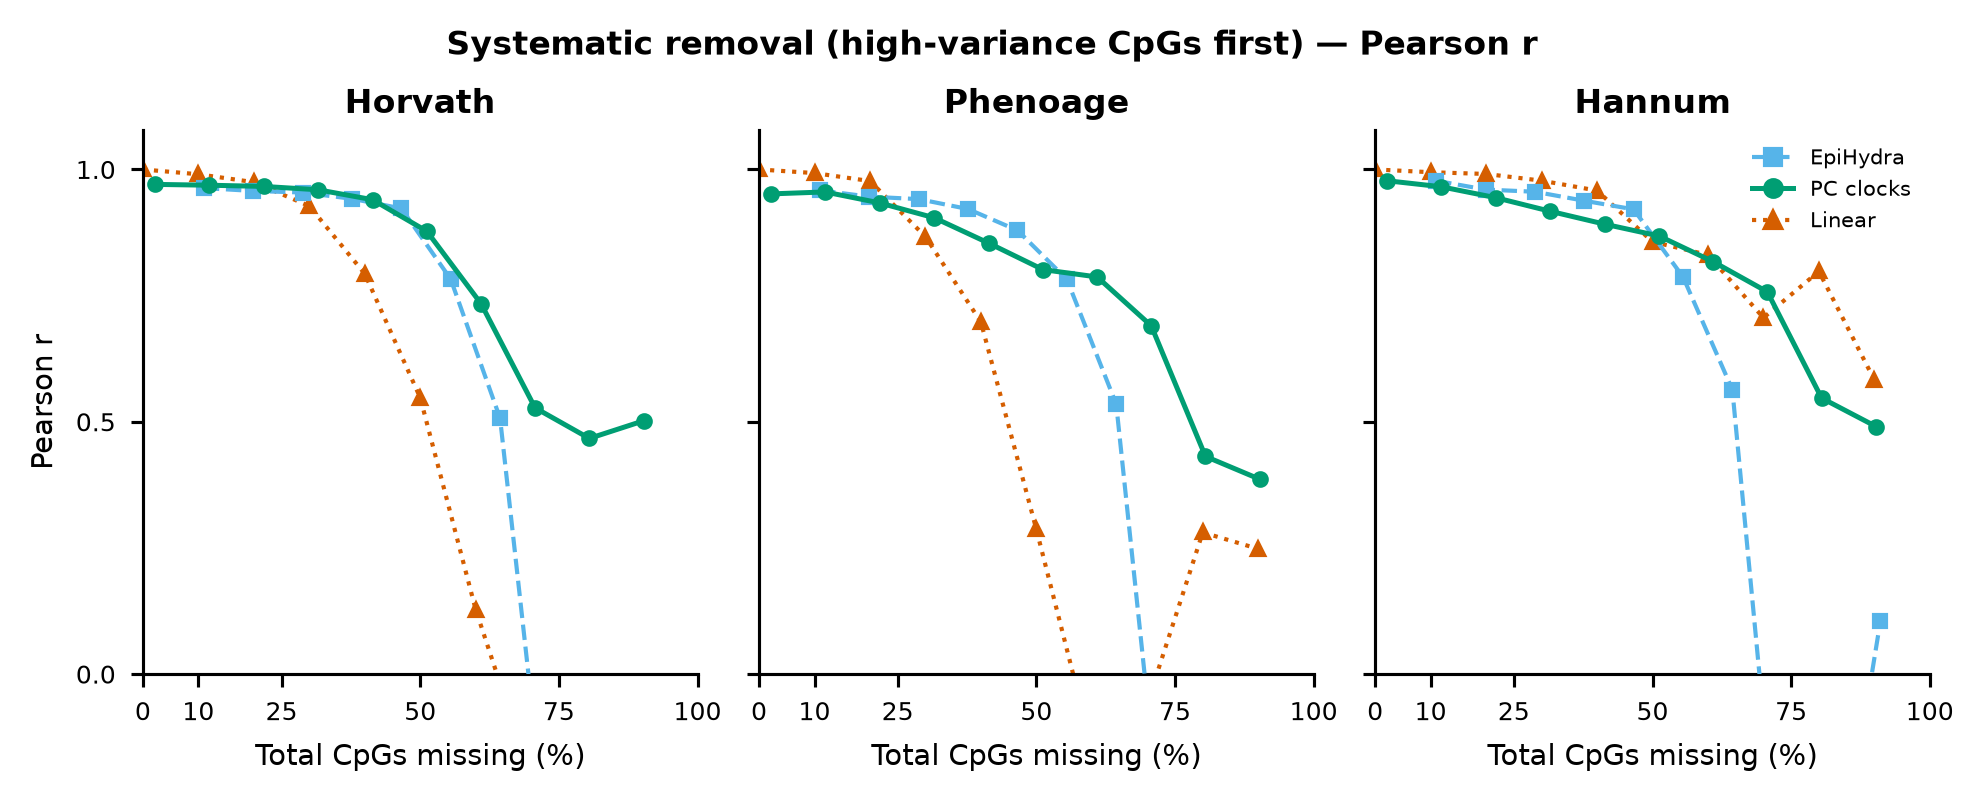

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/systematic_curves_r2.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/systematic_curves_r2.pdf


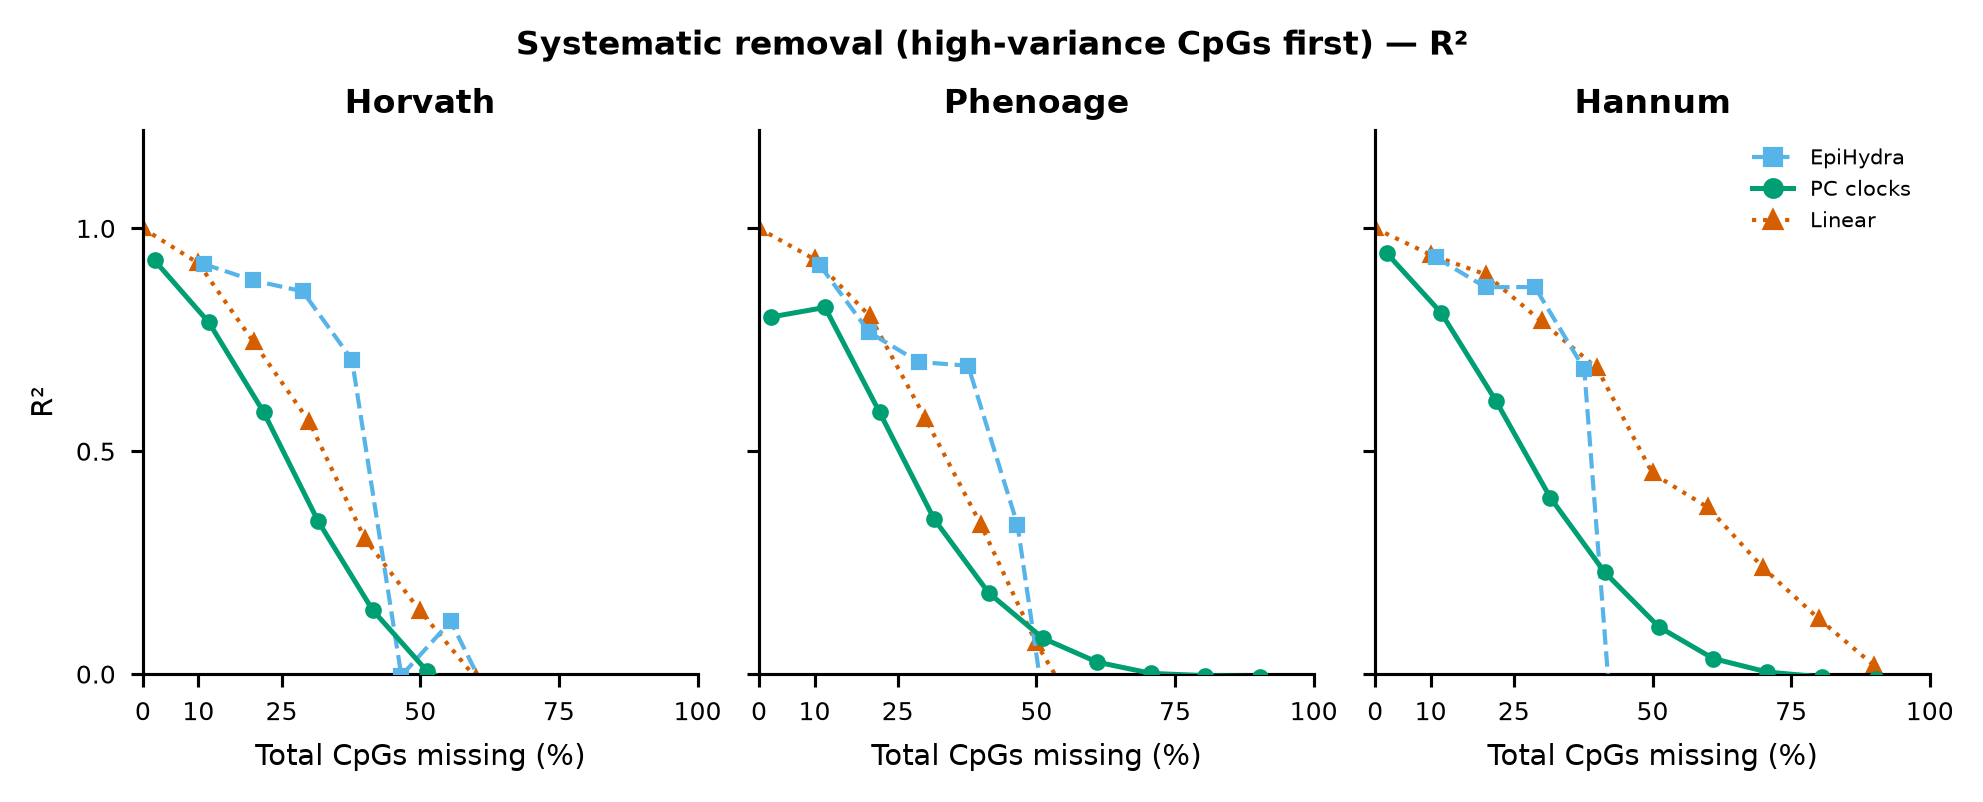

In [8]:
for metric in ('mae', 'pearson_r', 'r2'):
    fig, axes = plot_comparative_curves(
        systematic_all,
        clock_names=CLOCK_NAMES,
        metric=metric,
        x='total_missing',
        strategy_title='Systematic removal (high-variance CpGs first)',
        save_path=SAVE_DIR / f'systematic_curves_{metric}',
    )
    plt.show()

### 5.2 — Improvement over Linear (Δ MAE)

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/systematic_delta_mae.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/systematic_delta_mae.pdf


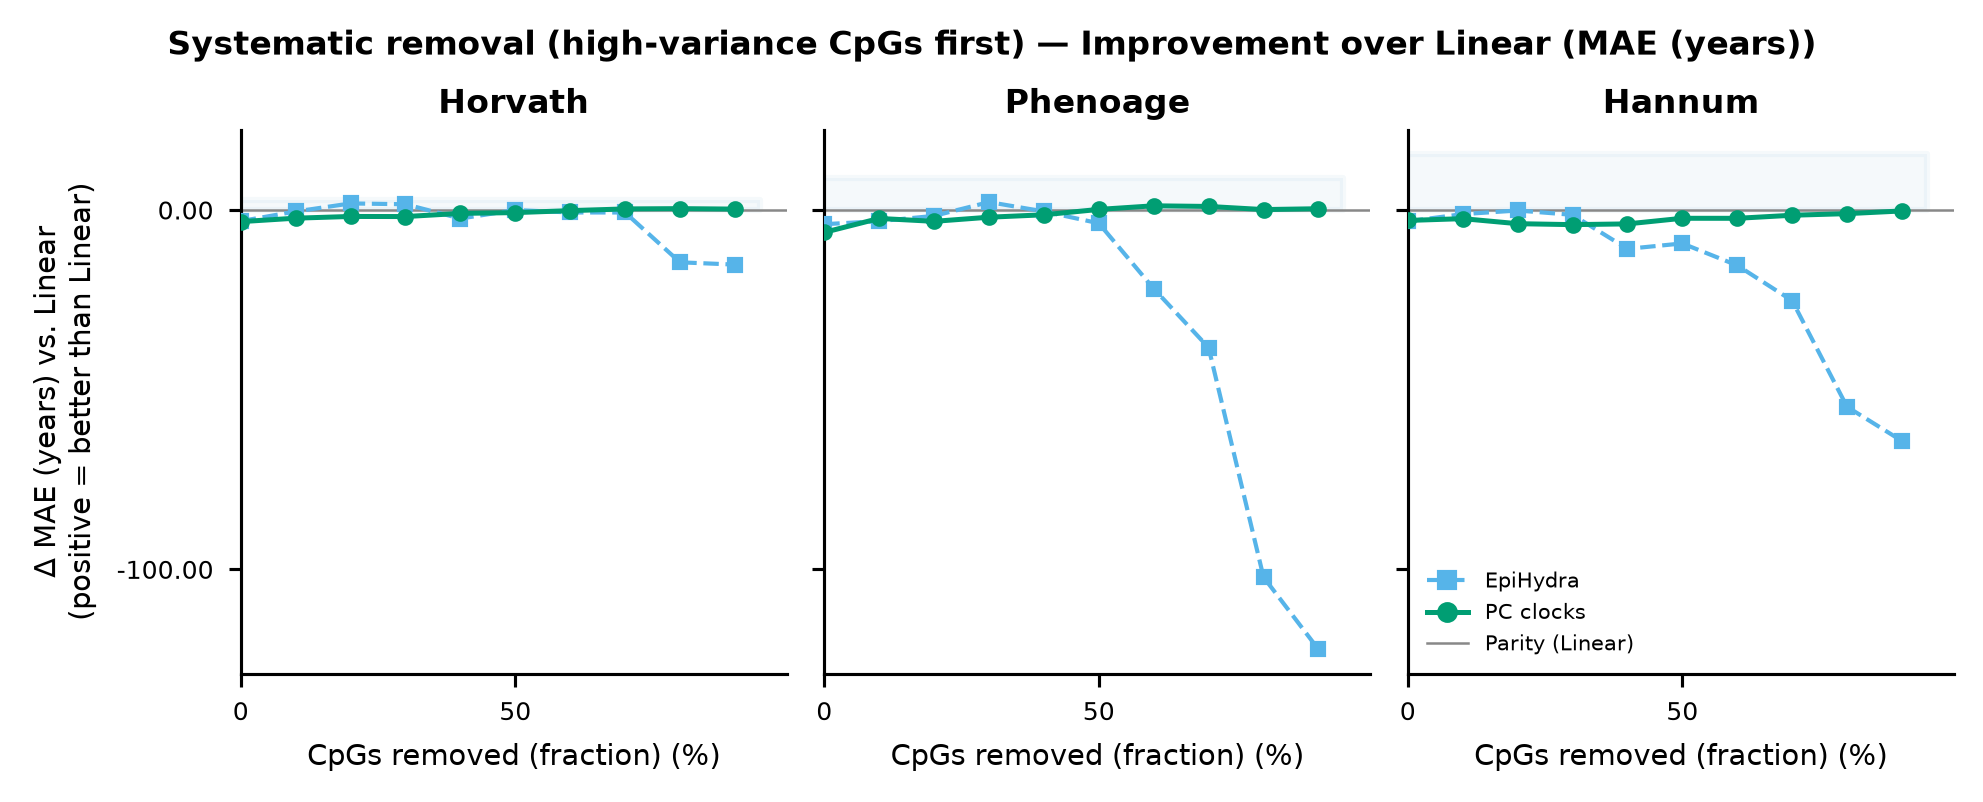

In [9]:
fig, axes = plot_delta_improvement(
    systematic_all,
    clock_names=CLOCK_NAMES,
    baseline='Linear',
    metric='mae',
    x='removal_frac',
    strategy_title='Systematic removal (high-variance CpGs first)',
    save_path=SAVE_DIR / 'systematic_delta_mae',
)
plt.show()

### 5.3 — Summary heatmap (MAE at key missingness levels)

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/systematic_heatmap_mae.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/systematic_heatmap_mae.pdf


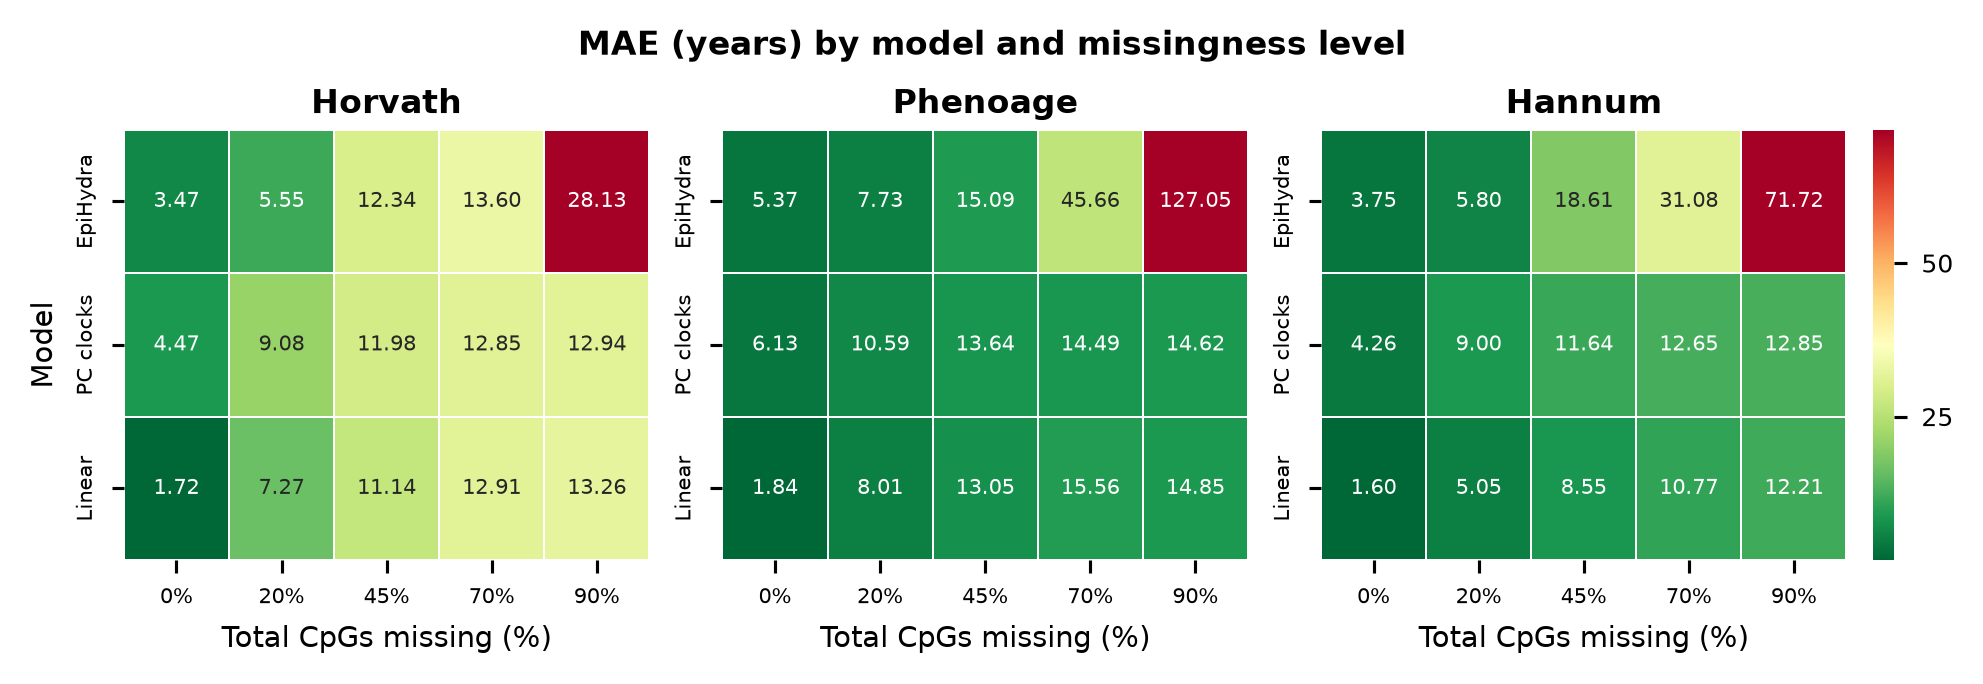

In [10]:
fig, axes = plot_summary_heatmap(
    systematic_all,
    clock_names=CLOCK_NAMES,
    metric='mae',
    missing_col='removal_frac',
    save_path=SAVE_DIR / 'systematic_heatmap_mae',
)
plt.show()

## 6 · Side-by-side strategy comparison

Direct comparison of random vs. systematic missingness for each model, showing whether probe identity (high-variance removal) degrades performance beyond uniform masking.

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/strategy_comparison_mae.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/strategy_comparison_mae.pdf


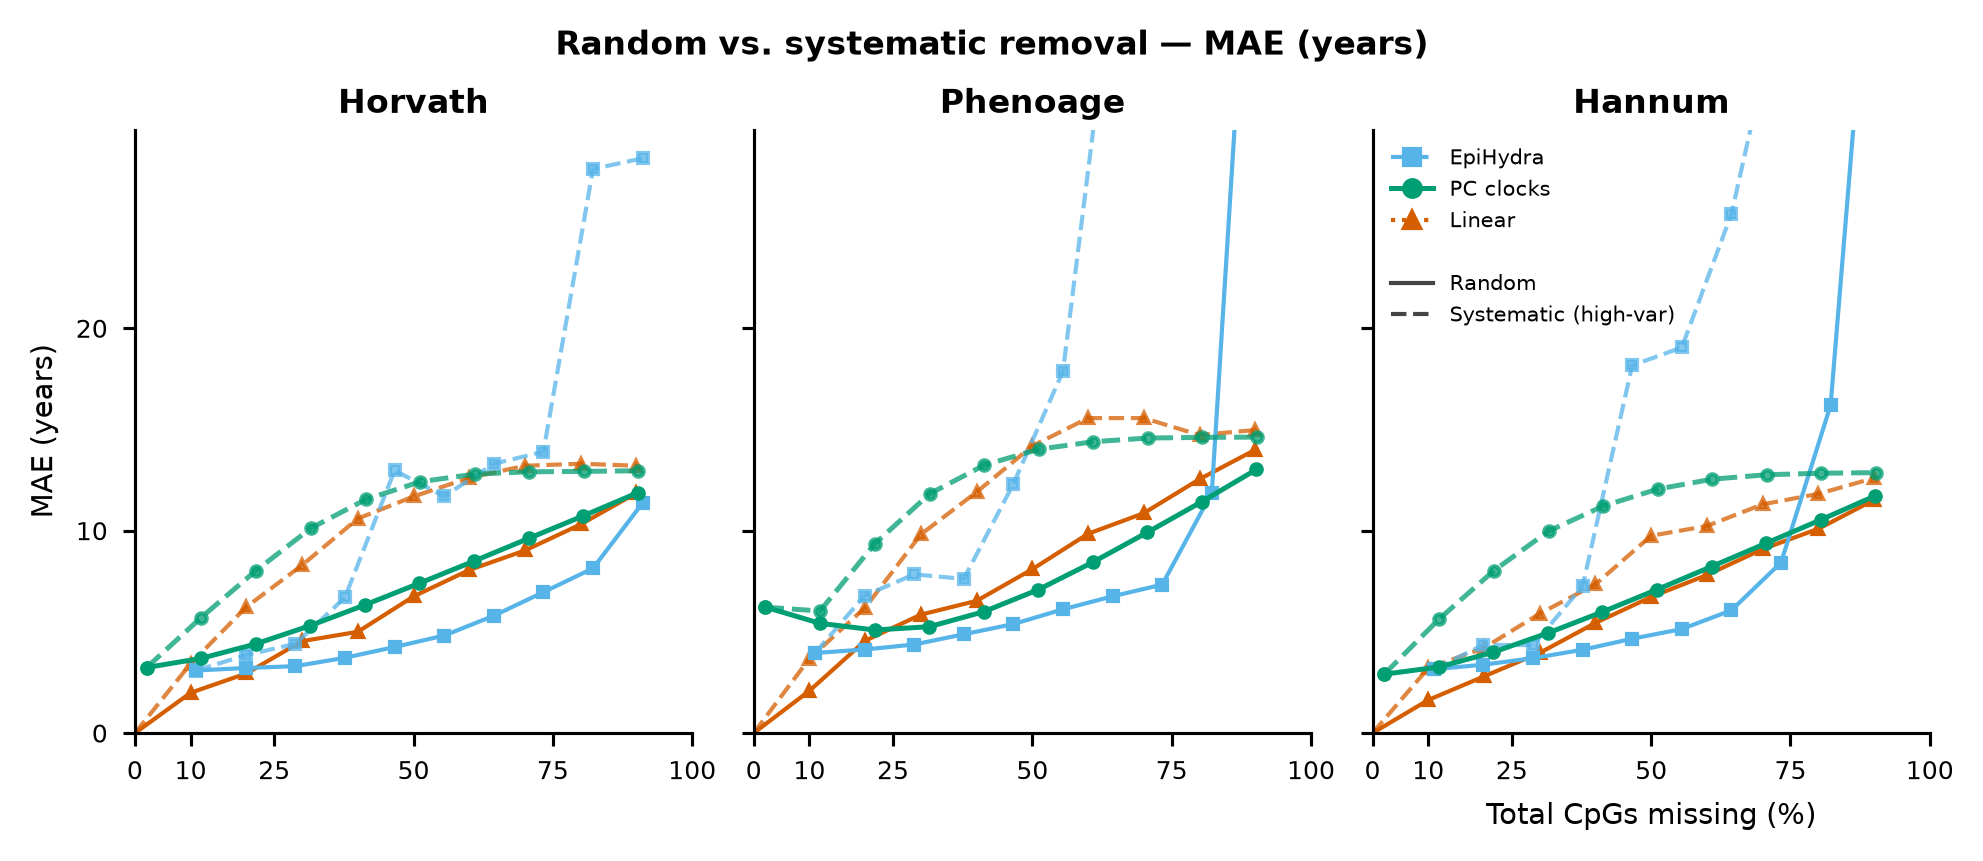

In [11]:
STRATEGY_STYLE = {
    'random':     {'ls': '-',  'alpha': 1.0, 'label': 'Random'},
    'systematic': {'ls': '--', 'alpha': 0.8, 'label': 'Systematic (high-var)'},
}

def plot_strategy_comparison(clock_names, metric='mae', save_path=None):
    """
    One subplot per clock (n panels total).
    All three models × two strategies overlaid as six lines per panel.
    Model = colour, strategy = line style (solid = random, dashed = systematic).
    """
    n = len(clock_names)
    fig_w = min(183, 55 * n) * _MM
    fig_h = 70 * _MM

    with plt.rc_context(_NM_RC):
        fig, axes = plt.subplots(
            1, n,
            figsize=(fig_w, fig_h),
            sharey=True,
            constrained_layout=True,
            squeeze=False,
        )
        axes = axes[0]

        for ax, clock in zip(axes, clock_names):
            for model in MODEL_ORDER:
                s = MODEL_STYLE[model]
                for strategy, strat_df, ss in [
                    ('random',     random_all,     {'ls': '-',  'alpha': 1.0, 'label': 'Random'}),
                    ('systematic', systematic_all, {'ls': '--', 'alpha': 0.75, 'label': 'Systematic'}),
                ]:
                    sub = strat_df[
                        (strat_df['model'] == model) &
                        (strat_df['clock'] == clock)
                    ].sort_values('total_missing')
                    if sub.empty:
                        continue
                    ax.plot(
                        sub['total_missing'] * 100,
                        sub[metric],
                        color=s['color'],
                        ls=ss['ls'],
                        lw=s['lw'],
                        marker=s['marker'],
                        markersize=2.5,
                        alpha=ss['alpha'],
                        zorder=s['zorder'],
                    )

            ax.set_title(_clean(clock), pad=4, fontweight='bold')
            ax.set_xlim(left=0)
            ax.set_xticks([0, 10, 25, 50, 75, 100])
            if not _HIGH_IS_GOOD[metric]:
                ax.set_ylim(bottom=0)
            if ax is axes[-1]:
                ax.set_xlabel('Total CpGs missing (%)')

        axes[0].set_ylabel(_METRIC_LABEL[metric])

        # Two-part legend: colour = model, line style = strategy
        model_handles = _legend_handles()
        strategy_handles = [
            Line2D([0], [0], color='#444', ls='-',  lw=1, label='Random'),
            Line2D([0], [0], color='#444', ls='--', lw=1, label='Systematic (high-var)'),
        ]
        axes[-1].legend(
            handles=model_handles + [Line2D([0],[0],color='none')] + strategy_handles,
            frameon=False, fontsize=5, loc='best',
        )

        fig.suptitle(
            f'Random vs. systematic removal — {_METRIC_LABEL[metric]}',
            fontsize=8, fontweight='bold',
        )

    if save_path is not None:
        for fmt in ('svg', 'pdf'):
            p = Path(str(save_path) + f'.{fmt}')
            p.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(p)
            print(f'Saved → {p}')

    return fig, axes


fig, axes = plot_strategy_comparison(
    CLOCK_NAMES,
    metric='mae',
    save_path=SAVE_DIR / 'strategy_comparison_mae',
)
plt.show()

## 7 · Extended metric exploration

Pearson *r* and R² for the systematic strategy (supplementary-style panels).

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/strategy_comparison_pearson_r.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/strategy_comparison_pearson_r.pdf


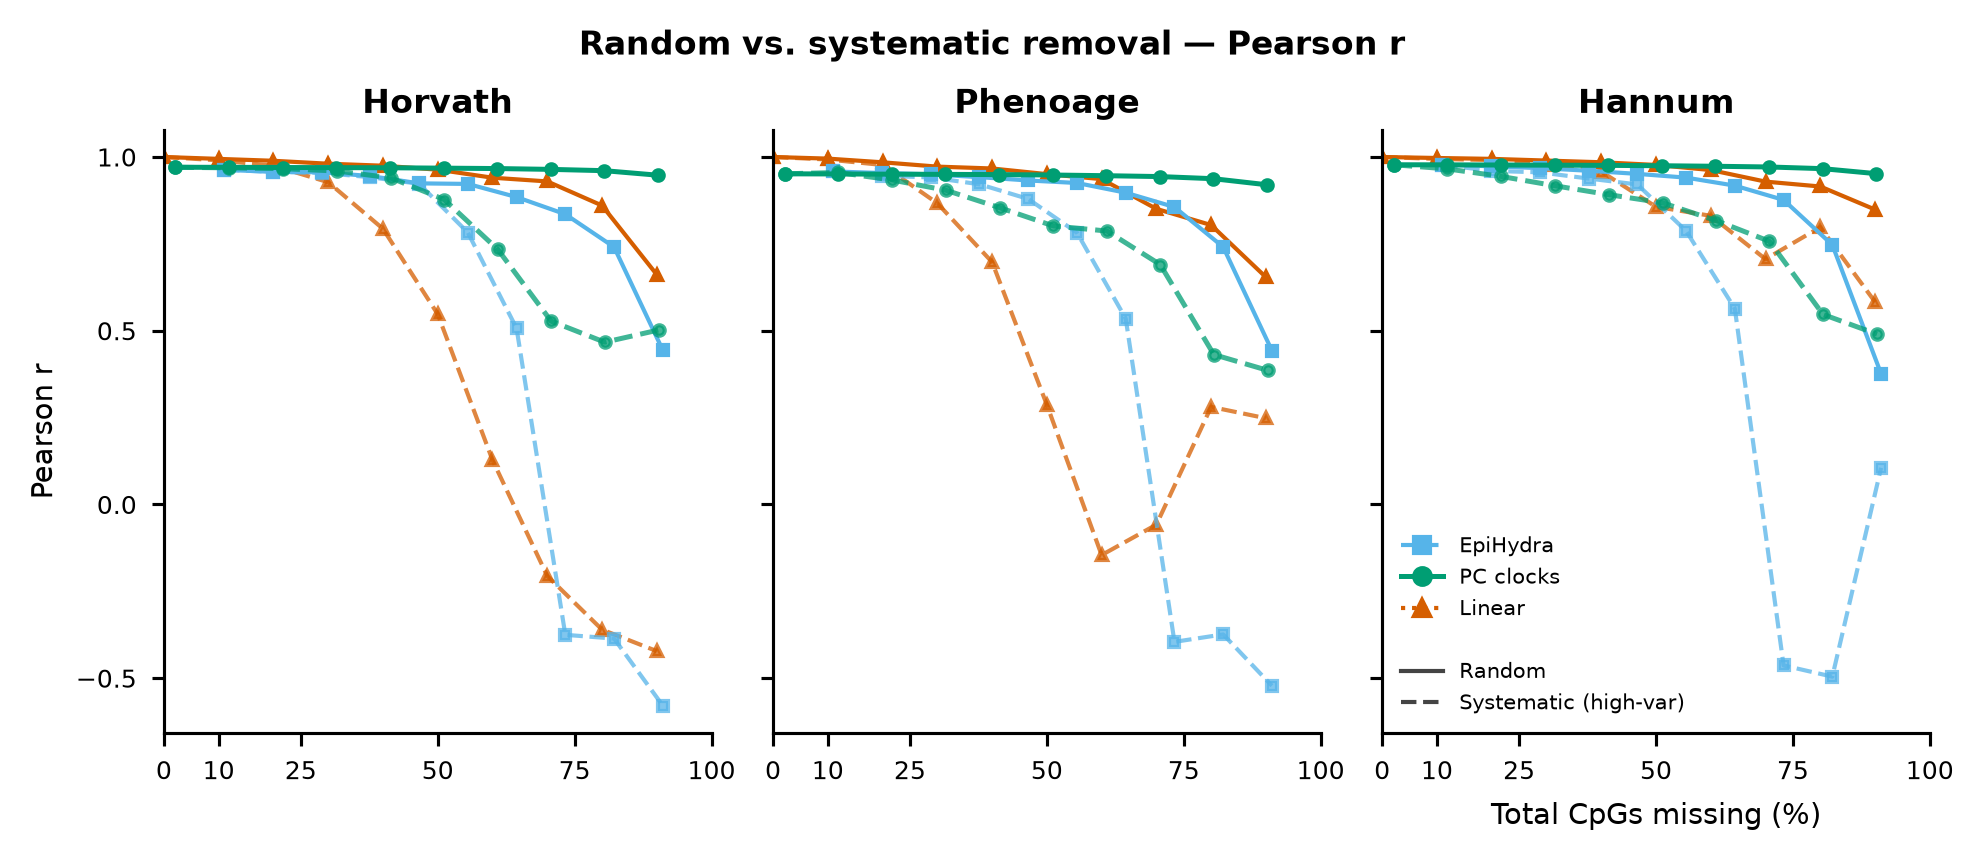

Saved → /work/gr-fe/bryan/EpiHydra/results/figures/strategy_comparison_r2.svg
Saved → /work/gr-fe/bryan/EpiHydra/results/figures/strategy_comparison_r2.pdf


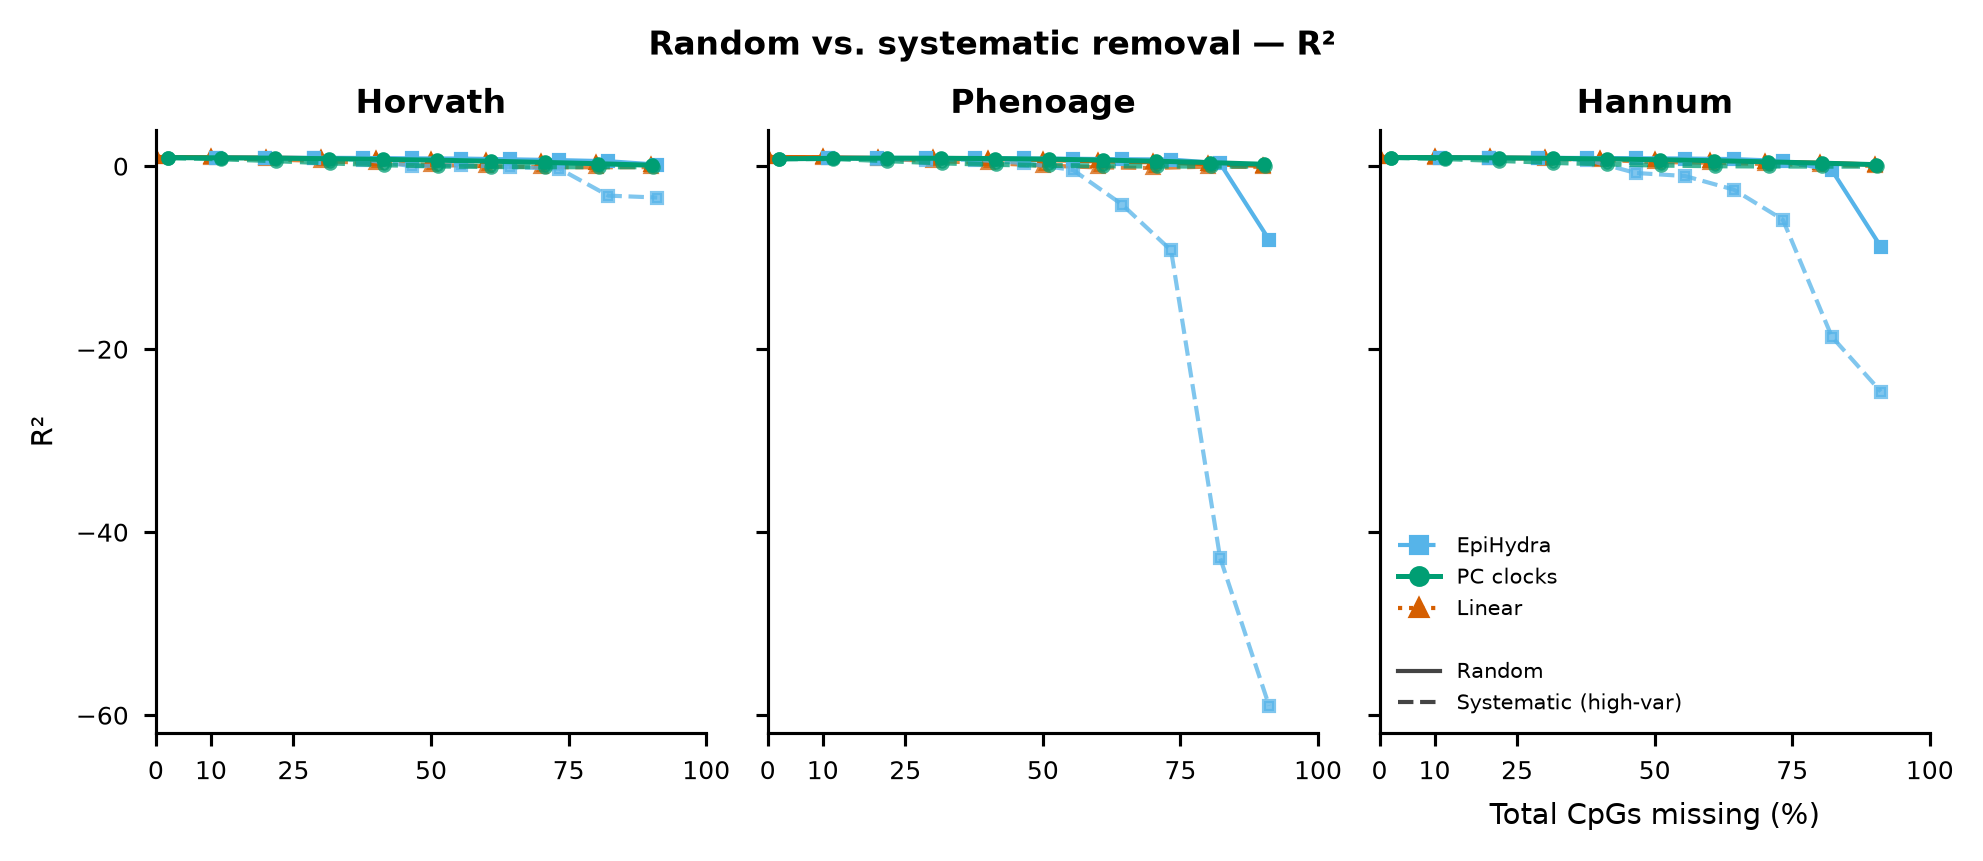

In [12]:
for metric in ('pearson_r', 'r2'):
    fig, axes = plot_strategy_comparison(
        CLOCK_NAMES,
        metric=metric,
        save_path=SAVE_DIR / f'strategy_comparison_{metric}',
    )
    plt.show()

## 8 · Export figure file manifest

In [ ]:
saved = sorted(SAVE_DIR.glob('*'))
print(f'{len(saved)} files in {SAVE_DIR}:\n')
for p in saved:
    print(f'  {p.name}')